In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\NEXUS\Downloads\uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 200000
Columns: 9


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [6]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [7]:
df.drop(['Unnamed: 0', 'key'], axis=1, inplace=True)
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [8]:
df.dropna(inplace=True)
print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [9]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'],utc=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   fare_amount        199999 non-null  float64            
 1   pickup_datetime    199999 non-null  datetime64[ns, UTC]
 2   pickup_longitude   199999 non-null  float64            
 3   pickup_latitude    199999 non-null  float64            
 4   dropoff_longitude  199999 non-null  float64            
 5   dropoff_latitude   199999 non-null  float64            
 6   passenger_count    199999 non-null  int64              
dtypes: datetime64[ns, UTC](1), float64(5), int64(1)
memory usage: 12.2 MB


In [10]:
df['year'] = df['pickup_datetime'].dt.year
df['month'] = df['pickup_datetime'].dt.month
df['day'] = df['pickup_datetime'].dt.day
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

In [11]:
df = df[df['passenger_count'].between(1, 6)]
print(df.shape)

(199290, 12)


In [12]:
df = df[
    df['pickup_longitude'].between(-74.3, -73.7) &
    df['dropoff_longitude'].between(-74.3, -73.7) &
    df['pickup_latitude'].between(40.4, 41.0) &
    df['dropoff_latitude'].between(40.4, 41.0)]
print(df.shape)

(194899, 12)


In [13]:
df = df[df['fare_amount'] > 0]
print(df['fare_amount'].describe())

count    194881.000000
mean         11.313760
std           9.583052
min           0.010000
25%           6.000000
50%           8.500000
75%          12.500000
max         499.000000
Name: fare_amount, dtype: float64


In [14]:
def haversine_distance(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2)
    distance = 2 * 6371 * np.arcsin(np.sqrt(a))
    return distance

In [15]:
df['distance_km'] = haversine_distance(df['pickup_latitude'],df['pickup_longitude'],df['dropoff_latitude'],df['dropoff_longitude'])

df[['pickup_latitude','pickup_longitude','dropoff_latitude','dropoff_longitude','distance_km','fare_amount']].head()

,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,distance_km,fare_amount
0,40.738354,-73.999817,40.723217,-73.999512,1.683323,7.5
1,40.728225,-73.994355,40.750325,-73.994710,2.457590,7.7
2,40.740770,-74.005043,40.772647,-73.962565,5.036377,12.9
3,40.790844,-73.976124,40.803349,-73.965316,1.661683,5.3
4,40.744085,-73.925023,40.761247,-73.973082,4.475450,16.0


In [16]:
df = df[(df['distance_km'] > 0) &(df['distance_km'] < 100)]
print(df.shape)

(192919, 13)


In [17]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df['fare_amount'] < lower_bound) |
    (df['fare_amount'] > upper_bound)
]

print("Number of fare outliers:", len(outliers))

Q1: 6.0
Q3: 12.5
IQR: 6.5
Lower Bound: -3.75
Upper Bound: 22.25
Number of fare outliers: 16434


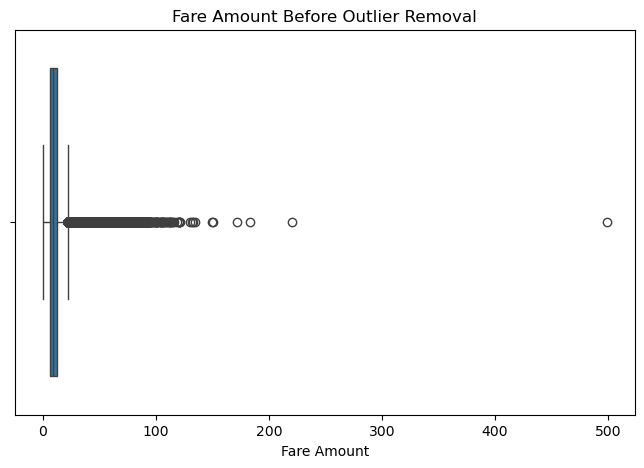

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['fare_amount'])

plt.title("Fare Amount Before Outlier Removal")
plt.xlabel("Fare Amount")
plt.show()

In [19]:
df = df[(df['fare_amount'] >= lower_bound) &(df['fare_amount'] <= upper_bound)]
print("Shape after removing fare outliers:", df.shape)

Shape after removing fare outliers: (176485, 13)


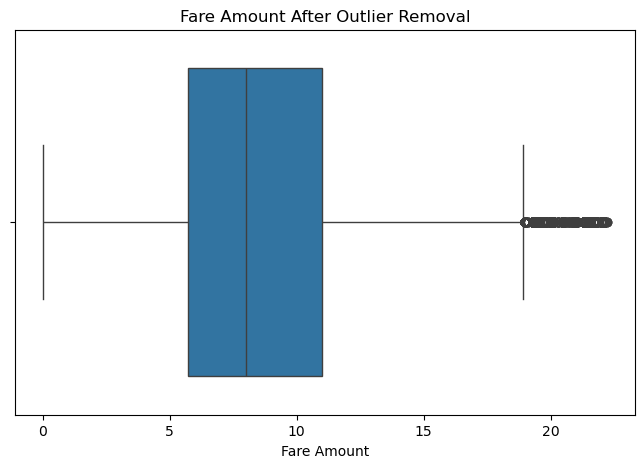

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['fare_amount'])

plt.title("Fare Amount After Outlier Removal")
plt.xlabel("Fare Amount")

plt.show()

In [21]:
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
correlation

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,day,hour,day_of_week,distance_km
fare_amount,1.000000,0.007116,-0.086929,0.101026,-0.097180,0.012949,0.135814,0.026707,0.006540,-0.013043,0.020445,0.804643
pickup_longitude,0.007116,1.000000,0.387356,0.575345,0.189653,-0.015417,-0.007132,0.000109,-0.001798,-0.002645,-0.018337,0.042789
pickup_latitude,-0.086929,0.387356,1.000000,0.165519,0.567784,-0.009507,-0.002257,0.000394,-0.000895,0.035395,-0.048605,-0.081224
dropoff_longitude,0.101026,0.575345,0.165519,1.000000,0.377744,-0.012289,-0.005141,-0.000736,-0.004168,-0.034978,-0.007008,0.151970
dropoff_latitude,-0.097180,0.189653,0.567784,0.377744,1.000000,-0.005721,0.001755,-0.000716,-0.002482,0.025195,-0.036370,-0.042849
passenger_count,0.012949,-0.015417,-0.009507,-0.012289,-0.005721,1.000000,0.002640,0.008618,0.002578,0.015350,0.037531,0.001727
year,0.135814,-0.007132,-0.002257,-0.005141,0.001755,0.002640,1.000000,-0.115167,-0.010724,0.002908,0.005507,-0.035087
month,0.026707,0.000109,0.000394,-0.000736,-0.000716,0.008618,-0.115167,1.000000,-0.016192,-0.003154,-0.009567,0.005198
day,0.006540,-0.001798,-0.000895,-0.004168,-0.002482,0.002578,-0.010724,-0.016192,1.000000,0.005563,0.004535,0.005722
hour,-0.013043,-0.002645,0.035395,-0.034978,0.025195,0.015350,0.002908,-0.003154,0.005563,1.000000,-0.088038,-0.037498


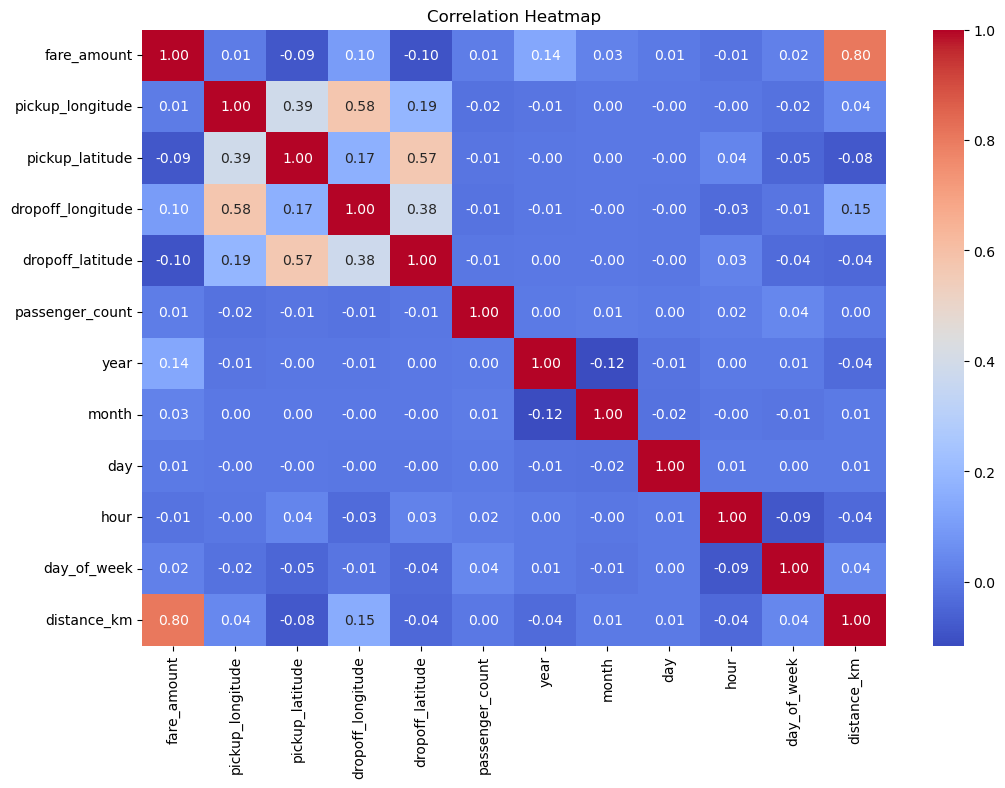

In [22]:
plt.figure(figsize=(12, 8))
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

In [23]:
X = df.drop(columns=['fare_amount','pickup_datetime'])
y = df['fare_amount']
print("Features:")
print(X.head())
print("\nTarget:")
print(y.head())

Features:
   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  year  month  day  hour  day_of_week  distance_km  
0                1  2015      5    7    19            3     1.683323  
1                1  2009      7   17    20            4     2.457590  
2                1  2009      8   24    21            0     5.036377  
3                3  2009      6   26     8            4     1.661683  
4                5  2014      8   28    17            3     4.475450  

Target:
0     7.5
1     7.7
2    12.9
3     5.3
4    16.0
Name: fare_amount, dtype: float64


In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (141188, 11)
Testing data: (35297, 11)


In [25]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

In [27]:
from sklearn.metrics import (r2_score,mean_squared_error,mean_absolute_error)
lr_r2 = r2_score(y_test, lr_pred)
lr_rmse = np.sqrt( mean_squared_error(y_test, lr_pred))
lr_mae = mean_absolute_error( y_test, lr_pred)

print("R2 Score:", lr_r2)
print("RMSE:", lr_rmse)
print("MAE:", lr_mae)

R2 Score: 0.665156314147748
RMSE: 2.3867338640455182
MAE: 1.6120176150623544


In [28]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100,max_depth=20,min_samples_leaf=2,random_state=42,n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [29]:
rf_r2 = r2_score(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mae = mean_absolute_error(y_test,rf_pred)

print("R2 Score:", rf_r2)
print("RMSE:", rf_rmse)
print("MAE:", rf_mae)

R2 Score: 0.7823533372579395
RMSE: 1.9242386977701065
MAE: 1.3230322703996638


In [30]:
comparison = pd.DataFrame({'Model': ['Linear Regression','Random Forest'],'R2 Score': [lr_r2,rf_r2],'RMSE': [lr_rmse,rf_rmse],'MAE': [lr_mae,rf_mae]})
comparison

,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.665156,2.386734,1.612018
1,Random Forest,0.782353,1.924239,1.323032


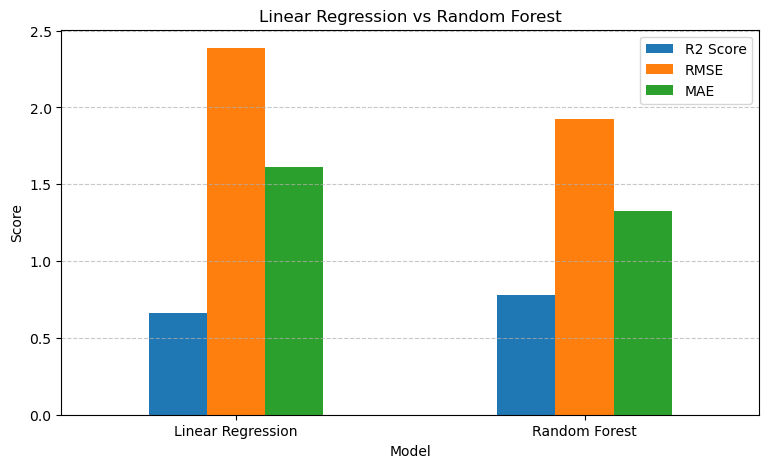

In [31]:
comparison.set_index('Model')[['R2 Score','RMSE','MAE']].plot(kind='bar',figsize=(9, 5))

plt.title("Linear Regression vs Random Forest")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

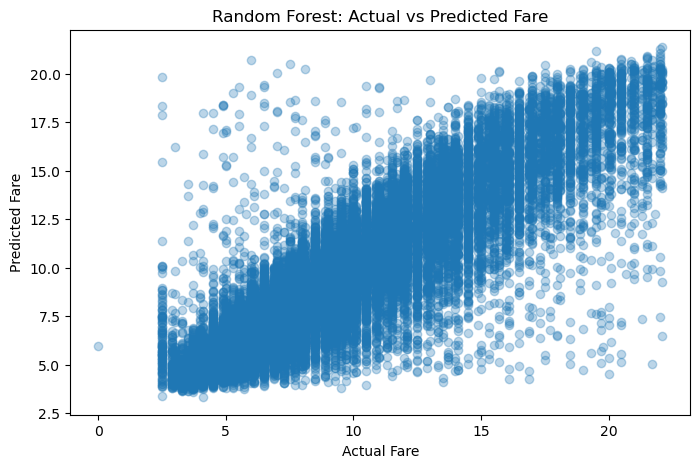

In [32]:
plt.figure(figsize=(8, 5))
plt.scatter( y_test, rf_pred,alpha=0.3)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Random Forest: Actual vs Predicted Fare")

plt.show()

In [33]:
importance = pd.DataFrame({'Feature': X.columns,'Importance': rf.feature_importances_})
importance = importance.sort_values( by='Importance', ascending=False)
print(importance)

              Feature  Importance
10        distance_km    0.761267
5                year    0.044072
3    dropoff_latitude    0.035547
2   dropoff_longitude    0.031176
0    pickup_longitude    0.028472
8                hour    0.025451
1     pickup_latitude    0.025297
7                 day    0.015858
6               month    0.015585
9         day_of_week    0.012503
4     passenger_count    0.004772


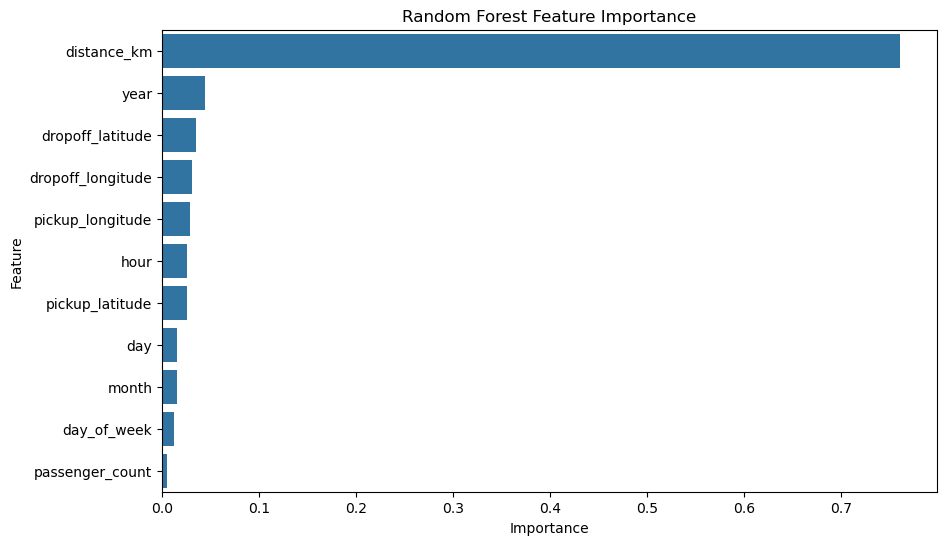

In [34]:
plt.figure(figsize=(10, 6))
sns.barplot( data=importance, x='Importance', y='Feature')
plt.title("Random Forest Feature Importance")
plt.show()